## this deck is to plot the interlayer spacings form literature 
and compare them to the results from the refinements. The goal is to see if the refinements are in agreement with the literature values, and if not, to see if there are any trends in the deviations.

In [31]:
def extractValues(structureFiles,pos1,pos2):
    Nb = []
    plotValues = {}
    for key in structureFiles.keys():
        df = structureFiles[key]
        NbVal = int(re.findall(r'\d+',key)[0])
        Nb.append(NbVal)
        for p1,p2 in zip(pos1,pos2):
            try:
                newList = plotValues[f'd{p1}_{p2}']
                newList.append(df.at[p1,p2])
                plotValues[f'd{p1}_{p2}'] = newList
            except:
                plotValues[f'd{p1}_{p2}'] = [df.at[p1,p2]]# NbRay = []
    return Nb, plotValues

In [32]:
def extractValues(structureFiles,pos1,pos2):
    Nb = []
    plotValues = {}
    for key in structureFiles.keys():
        df = structureFiles[key]
        NbVal = int(re.findall(r'\d+',key)[0])
        Nb.append(NbVal)
        for p1,p2 in zip(pos1,pos2):
            try:
                newList = plotValues[f'd{p1}_{p2}']
                newList.append(df.at[p1,p2])
                plotValues[f'd{p1}_{p2}'] = newList
            except:
                plotValues[f'd{p1}_{p2}'] = [df.at[p1,p2]]# NbRay = []
    return Nb, plotValues

In [33]:
def extractValues_nonSym(structureFiles,pos1,pos2):
    Nb = []
    plotValues = {}
    for key in structureFiles.keys():
        df = structureFiles[key]
        NbVal = int(re.findall(r'\d+',key)[0])
        Nb.append(NbVal)
        for p1,p2 in zip(pos1,pos2):
            try:
                newList = plotValues[f'd{p1}_{p2}']
                newList.append(df.at[p1,p2])
                plotValues[f'd{p1}_{p2}'] = newList
            except:
                plotValues[f'd{p1}_{p2}'] = [df.at[p1,p2]]# NbRay = []
    return Nb, plotValues

In [34]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [35]:
inputFolder = r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\Structures\ILSpacingsJoubert"
inputPath = Path(inputFolder)
exportFolder = r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\muPhaseEval_results"
exportFolder = Path(exportFolder)

In [36]:
inputFiles = list(inputPath.glob('*.csv'))
inputFiles

[WindowsPath('I:/sciebo/Paper6_OccupancyAndEffectsInNbNi/muphase_stuff - Kopie/Structures/ILSpacingsJoubert/Nb496N504_joubert_ILSpacings.csv'),
 WindowsPath('I:/sciebo/Paper6_OccupancyAndEffectsInNbNi/muphase_stuff - Kopie/Structures/ILSpacingsJoubert/Nb518Ni482_joubert_ILSpacings.csv'),
 WindowsPath('I:/sciebo/Paper6_OccupancyAndEffectsInNbNi/muphase_stuff - Kopie/Structures/ILSpacingsJoubert/Nb530Ni470_joubert_ILSpacings.csv'),
 WindowsPath('I:/sciebo/Paper6_OccupancyAndEffectsInNbNi/muphase_stuff - Kopie/Structures/ILSpacingsJoubert/Nb553Ni447_joubert_ILSpacings.csv'),
 WindowsPath('I:/sciebo/Paper6_OccupancyAndEffectsInNbNi/muphase_stuff - Kopie/Structures/ILSpacingsJoubert/Nb569Ni431_joubert_ILSpacings.csv')]

In [37]:
structureFiles ={}
for file in inputFiles:
    df = pd.read_csv(file,index_col=0)
    structureFiles[file.stem] = df



In [38]:
## read il spacings from vario8us folders (extracted from .cif files using matlab scritp in astro_sripts/decks/structureAnalysis/IlSpacings)


inputFolder = r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\Structures\ILSpacingsNbCoRay"
inputPath = Path(inputFolder)
inputFiles = list(inputPath.glob('*.csv'))
structureFilesRayNbCo ={}
for file in inputFiles:
    df = pd.read_csv(file,index_col=0)
    structureFilesRayNbCo[file.stem] = df


inputFolder = r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\Structures\ILSpacingsNbNiRay"
inputPath = Path(inputFolder)
inputFiles = list(inputPath.glob('*.csv'))
structureFilesRayNbNi ={}
for file in inputFiles:
    df = pd.read_csv(file,index_col=0)
    structureFilesRayNbNi[file.stem] = df

inputFolder = r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\Structures\ILSpacingsOtherLit"
inputPath = Path(inputFolder)
inputFiles = list(inputPath.glob('*.csv'))
structureFilesOther ={}
for file in inputFiles:
    df = pd.read_csv(file,index_col=0)
    structureFilesOther[file.stem] = df

inputFolder = r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\Structures\IlSpacingsFitStructures"
inputPath = Path(inputFolder)
inputFiles = list(inputPath.glob('*.csv'))
structureFilesFitParams ={}
for file in inputFiles:
    df = pd.read_csv(file,index_col=0)
    structureFilesFitParams[file.stem] = df



## clean the simulation for Nb7Ni6

# keys = ['3a','18h','6c1','6c2','6c3']
# df_temp = structureFilesRayNbNi["Nb7Ni6_relaxed_ray_ILSpacings"]
# df_tempNew = pd.DataFrame(index=keys,columns=keys)
# i= 0
# for colkey in keys:
#     j=0
#     for rowKey in keys:
#         colFilter = [x for x in df_temp.columns.values if colkey in x]
#         rowFilter = [x for x in df_temp.columns.values if rowKey in x]
#         # df_temp[rowFilter].columns.values
#         if i>j:
#             minSpacing = df_temp.loc[rowFilter,colFilter].min().min() # min of each column, then min of all values
#         else:
#             minSpacing = df_temp.loc[rowFilter,colFilter].min().mean()
#         df_tempNew.loc[rowKey,colkey] = minSpacing  
        
#         j=j+1
#     i=i+1
# df_tempNew  
# structureFilesRayNbNi["Nb7Ni6_relaxed_ray_ILSpacings"]=df_tempNew


ILSpacingsExperimentalEBSD = pd.read_csv(r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\muPhaseEval_results\IL_results.csv",index_col=0)
# ltest just hard code this. Qucickes tfo r this.
ILSpacingsExperimentalEBSD["Nb"]=[48.5,50.5,55.5,55.6] #48Nb52Co,51Nb49Ni,56Nb44Co,58Nb-42Ni
ILSpacingsExperimentalEBSD["Nb_std"]=[0.5,0.5,0.5,0.5]
 ## from the EDS analysis
# ILSpacingsExperimentalEBSD["type"] = ["N]


ILSpacingsExperimentalHRTEM = pd.read_csv(r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\muPhaseEval_results\IL_results_HRTEM.csv",index_col=0)
# ltest just hard code this. Qucickes tfo r this.
ILSpacingsExperimentalHRTEM["Nb"]=[50.5,55.6] #48Nb52Co,51Nb49Ni,56Nb44Co,58Nb-42Ni
ILSpacingsExperimentalHRTEM["Nb_std"]=[0.5,0.5]
 ## from the EDS analysis
# ILSpacingsExperimentalEBSD["type"] = ["N]


# IL_results_HRTEM

In [39]:
path_51Nb = Path(r"I:\sciebo\Cooperations\spark\Spark_Nb51Ni49\0005")
path_51Nb =  path_51Nb.joinpath('min_distances_stats.txt')
df_51Nb_HRTM  = pd.read_csv(path_51Nb)
df_51Nb_HRTM = df_51Nb_HRTM.pivot(columns='array_index')
df_51Nb_HRTM['Nb'] = 50.5


path_58Nb = Path( r"I:\sciebo\Cooperations\spark\Spark_Nb58Ni42\0034")
path_58Nb =  path_58Nb.joinpath('min_distances_stats.txt')
df_58Nb_HRTM  = pd.read_csv(path_58Nb)
df_58Nb_HRTM = df_58Nb_HRTM.pivot(columns='array_index')
df_58Nb_HRTM['Nb'] = 55.6

ILSpacingsExperimentalHRTEM = pd.concat([df_51Nb_HRTM,df_58Nb_HRTM])#pd.read_csv(r"I:\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\muPhaseEval_results\IL_results_HRTEM.csv",index_col=0)
# ltest just hard code this. Qucickes tfo r this.
# ILSpacingsExperimentalHRTEM["Nb"]=[50.5,55.6] #48Nb52Co,51Nb49Ni,56Nb44Co,58Nb-42Ni
# ILSpacingsExperimentalHRTEM["Nb_std"]=[0.5,0.5]

In [40]:
ILSpacingsExperimentalHRTEM[('mean','d_t')]

0    0.386823
1         NaN
2         NaN
3         NaN
0    0.436051
1         NaN
2         NaN
3         NaN
Name: (mean, d_t), dtype: float64

In [41]:

# df_tmep

In [42]:
# # for i, sample in enumerate(ILSpacingsExperimentalHRTEM.index):
# ax[0].scatter(ILSpacingsExperimentalHRTEM['Nb']
#               ,ILSpacingsExperimentalHRTEM['3amean'],
#               label='HR-TEM, Nb-Ni, this study',color='black',alpha=0.5,marker='d')


# ax[0].errorbar(ILSpacingsExperimentalHRTEM['Nb']
#               ,ILSpacingsExperimentalHRTEM['3amean'],yerr=ILSpacingsExperimentalHRTEM['3astd'],capsize=2,
#                    markersize=5,
#                    color='black',linewidth = 0,elinewidth = 0.5,alpha=0.5)


# ax[1].scatter(ILSpacingsExperimentalHRTEM['Nb']
#               ,ILSpacingsExperimentalHRTEM['18hmean'],
#               label='HR-TEM, Nb-Ni, this study',color='black',alpha=0.5,marker='d')


# ax[1].errorbar(ILSpacingsExperimentalHRTEM['Nb']
#               ,ILSpacingsExperimentalHRTEM['18hmean'],yerr=ILSpacingsExperimentalHRTEM['18hstd'],capsize=2,
#                    markersize=5,
#                    color='black',linewidth = 0,elinewidth = 0.5,alpha=0.5)


In [43]:
# inputFolder = r"C:\Users\berners\sciebo\Paper6_OccupancyAndEffectsInNbNi\muphase_stuff - Kopie\Structures\ILSpacingsNbNiRay"
# inputPath = Path(inputFolder)
# inputFiles = list(inputPath.glob('*.csv'))
# structureFilesRayNbNi ={}
# for file in inputFiles:
#     df = pd.read_csv(file,index_col=0)
#     structureFilesRayNbNi[file.stem] = df

In [44]:
# structureFilesRayNbNi["Nb7Ni6_relaxed_ray_ILSpacings"]


In [45]:
structureFilesRayNbNi

{'Nb6Ni7_relaxed_nisa_ILSpacings':           18h        3a       6c1       6c2       6c3
 Row                                                  
 18h  0.000000  2.005093  2.331198  1.714413  1.100690
 3a   2.005084  0.000000  4.336281  0.290671  3.105774
 6c1  2.331198  4.336273  0.000000  4.045611  1.230508
 6c2  1.714413  0.290679  4.045611  0.000000  2.815103
 6c3  1.100690  3.105783  1.230508  2.815103  0.000000,
 'Nb7Ni6_relaxed_Nisa_ILSpacings':           18h        3a       6c1       6c2       6c3
 Row                                                  
 18h  0.000000  2.112438  2.306364  1.735645  1.078433
 3a   2.112438  0.000000  4.418802  0.376793  3.190870
 6c1  2.306364  4.418802  0.000000  4.042009  1.227932
 6c2  1.735645  0.376793  4.042009  0.000000  2.814077
 6c3  1.078433  3.190870  1.227932  2.814077  0.000000}

In [46]:
ILSpacingsExperimentalEBSD
for df, key in zip(structureFilesFitParams.values(),structureFilesFitParams.keys()):
    print(f'{key}: diff 6c2, 18h: {df.loc["6c2","18h"]}')
    print(f'{key}: diff 3a, 18h: {df.loc["3a","6c2"]}')
    # print(f'{"3a","6c2"]}')
    print(df.loc["3a","6c2"] + df.loc["18h","6c2"])
    # print(df.loc["3a","6c2"] + df.loc["6c2","18h"])
        #   "")
    # print(key)
ILSpacingsExperimentalEBSD["6c2+18h"]= [2.0206, 2.0683,2.04049,2.0845] #48Nb52Co,51Nb49Ni,56Nb44Co,58Nb-42N

NbCo_a4.92_c26.25_LowNb_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020_ILSpacings: diff 6c2, 18h: 1.69563386676667
NbCo_a4.92_c26.25_LowNb_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020_ILSpacings: diff 3a, 18h: 0.324994231066667
2.020628097833337
NbCo_a4.92_c26.25_LowNb_6c2-0.400_3aNb-1.000__19.4kV_dmin0.020_ILSpacings: diff 6c2, 18h: 1.62062308456667
NbCo_a4.92_c26.25_LowNb_6c2-0.400_3aNb-1.000__19.4kV_dmin0.020_ILSpacings: diff 3a, 18h: 0.400005013266667
2.020628097833337
NbCo_a4.98_c26.50_HighNb_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020_ILSpacings: diff 6c2, 18h: 1.71548259676667
NbCo_a4.98_c26.50_HighNb_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020_ILSpacings: diff 3a, 18h: 0.325008491066664
2.040491087833334
NbCo_a4.98_c26.50_HighNb_6c2-0.400_3aNb-1.000__19.4kV_dmin0.020_ILSpacings: diff 6c2, 18h: 1.64050306366667
NbCo_a4.98_c26.50_HighNb_6c2-0.400_3aNb-1.000__19.4kV_dmin0.020_ILSpacings: diff 3a, 18h: 0.399988024166669
2.040491087833339
NbNi_c26.81_a4.92_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020_ILSpacings:

In [47]:
ILSpacingsExperimentalEBSD

,0mean,0std,Nb,Nb_std,6c2+18h
Sample,,,,,
48Nb52Co,0.361315,0.007938,48.5,0.5,2.02060
51Nb-49Ni,0.380390,0.012182,50.5,0.5,2.06830
56Nb44Co,0.399021,0.012287,55.5,0.5,2.04049
58Nb-42Ni,0.420002,0.007753,55.6,0.5,2.08450


In [48]:
import re

string = "Nb47Ni53_joubert_ILSpacings"
matches = re.findall(r'(\D*)(\d+)', string)

# This will create a list of tuples with (word, number)
result = [(word, number) for word, number in matches]

print(result)

[('Nb', '47'), ('Ni', '53')]


In [49]:
# fig,ax = plt.subplots(figsize=(15,15))
# ax.imshow(structureFilesRayNbNi["Nb7Ni6_relaxed_ray_ILSpacings"])
# fig.colorbar
# ax.set_xticks(np.arange(0,len(structureFilesRayNbNi["Nb7Ni6_relaxed_ray_ILSpacings"].columns)))
# ax.set_xticklabels(structureFilesRayNbNi["Nb7Ni6_relaxed_ray_ILSpacings"],rotation=90)
# ax.set_yticks(np.arange(0,len(structureFilesRayNbNi["Nb7Ni6_relaxed_ray_ILSpacings"].columns)))
# ax.set_yticklabels(structureFilesRayNbNi["Nb7Ni6_relaxed_ray_ILSpacings"])

In [50]:

pos1 = ['3a','18h']#,'18h','6c3']
pos2 = ['6c2','6c2']#,'6c3','6c1']
Nb, plotValues = extractValues(structureFiles,pos1,pos2)
NbRay, plotValuesRay = extractValues(structureFilesRayNbCo,pos1,pos2)

NbOther, plotValuesOther = extractValues(structureFilesOther,pos1,pos2)


# pos1 = ['3a_1','18h_1','6c3_2']
# pos2 = ['6c2_1','6c2_2','6c3_2','6c1_2']
NbNiRay, plotValuesNbNiRay = extractValues(structureFilesRayNbNi,pos1,pos2)

# d_3a_6c2Ray = []
# d_18h_6c2 = []
# d_18h_6c3 = []
# d_6c3_6c1 = []
# for key in structureFiles.keys():
#     df = structureFiles[key]
#     NbVal = int(re.findall(r'\d+',key)[0])
#     Nb.append(NbVal)
#     d_3a_6c2.append(df.at['3a','6c2'])
#     d_18h_6c2.append(df.at['18h','6c2'])
#     d_18h_6c3.append(df.at['18h','6c3'])
#     d_6c3_6c1.append(df.at['6c3','6c1'])
plotValuesNbNiRay 

{'d3a_6c2': [np.float64(0.290670650224), np.float64(0.376793326581666)],
 'd18h_6c2': [np.float64(1.714413181392), np.float64(1.73564452154333)]}

In [51]:
from matplotlib import colors
# cols_rgb = []
# for col in colorList[:][0]:
#   temp = []
#   for col_i in colors.to_rgb(col):
#     temp.append(col_i)
#   cols_rgb.append(temp)
# # new_col  =[colors.to_rgb(colorList[1][0]),colors.to_rgb(colorList[2][0])]
# # new_col  =
# cols_rgb = np.array(cols_rgb)
# l1 = cols_rgb[0,:]+cols_rgb[2,:]
# l1 = colors.to_rgb(tuple(l1/2))
# l2 = cols_rgb[1,:]+cols_rgb[3,:]
# l2 = colors.to_rgb(tuple(l2/2))
# l1,l2

In [52]:
ILSpacingsExperimentalHRTEM

mean                              standard_deviation  \
array_index       d_t      d_tK    d_t_m1   d_t_m2                d_t   
0            0.386823       NaN       NaN      NaN           0.035400   
1                 NaN       NaN  0.386823      NaN                NaN   
2                 NaN       NaN       NaN  1.62355                NaN   
3                 NaN  1.623550       NaN      NaN                NaN   
0            0.436051       NaN       NaN      NaN           0.035163   
1                 NaN       NaN  0.436051      NaN                NaN   
2                 NaN  1.617146       NaN      NaN                NaN   
3                 NaN       NaN       NaN      NaN                NaN   

                                             Nb      mean standard_deviation  
array_index      d_tK    d_t_m1    d_t_m2         d_tK_m1            d_tK_m1  
0                 NaN       NaN       NaN  50.5       NaN                NaN  
1                 NaN  0.035408       NaN  50.5       NaN                NaN  
2                 NaN       NaN  0.067085  50.5       NaN                NaN  
3            0.067102       NaN       NaN  50.5       NaN                NaN  
0                 NaN       NaN       NaN  55.6       NaN                NaN  
1                 NaN  0.035171       NaN  55.6       NaN                NaN  
2            0.017841       NaN       NaN  55.6       NaN                NaN  
3                 NaN       NaN       NaN  55.6  1.617146           0.017845

0
1
48Nb52Co
51Nb-49Ni
56Nb44Co
58Nb-42Ni


C:\Users\berners\AppData\Local\Temp\ipykernel_3840\351131780.py:152: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(pad = 10)


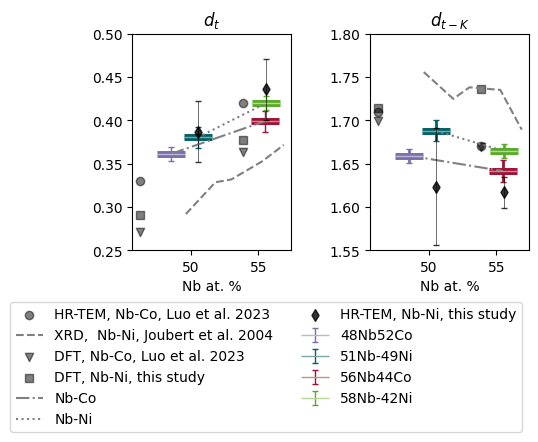

In [53]:


import matplotlib.ticker as ticker
from RWTHColors import ColorManager
colMan = ColorManager()
colorList =[[colMan.RWTHLila.p(100),colMan.RWTHLila.p(75),colMan.RWTHLila.p(50),colMan.RWTHLila.p(25)],
            [colMan.RWTHPetrol.p(100),colMan.RWTHPetrol.p(75),colMan.RWTHPetrol.p(50),colMan.RWTHOrange.p(25)],            
            [colMan.RWTHBordeaux.p(100),colMan.RWTHBordeaux.p(75),colMan.RWTHBordeaux.p(50),colMan.RWTHBordeaux.p(25)],
            [colMan.RWTHGruen.p(100),colMan.RWTHGruen.p(75),colMan.RWTHGruen.p(50),colMan.RWTHGruen.p(25)]]


plt.style.use('default')
cm = 1/2.54
cmScalingFactor = 1.3

fig,ax = plt.subplots(1,2,figsize=(10*cm*cmScalingFactor,5.5*cm*cmScalingFactor))#, constrained_layout=True)
# for i:5
Nb6Co7_dt_luo = 0.33
Nb6Co7_dtk_luo = 1.71
Nb7Co6_dt_luo = 0.42
Nb7Co6_dtk_luo = 1.67


titlList = {"d3a_6c2":"$d_{t}$","d18h_6c2":"$d_{t-K}$","d18h_6c3":"$d_{k-CN14}$","d6c3_6c1":"$d_{CN14-CN15}$"}





yLim = 0.2
ax[0].scatter(6/(6+7)*100,Nb6Co7_dt_luo,label='HR-TEM, Nb-Co, Luo et al. 2023',color='black',alpha=0.5)
ax[0].scatter(7/(6+7)*100,Nb7Co6_dt_luo,color='black',alpha=0.5)

ax[1].scatter(6/(6+7)*100,Nb6Co7_dtk_luo,label='HR-TEM, Nb-Co, Luo et al. 2023',color='black',alpha=0.5)
ax[1].scatter(7/(6+7)*100,Nb7Co6_dtk_luo,color='black',alpha=0.5)
for iii,key in zip(range(0,len(plotValues)),plotValues.keys()):
    print(iii)
    ax[iii].plot(np.array(Nb)/10,plotValues[key],label = 'XRD,  Nb-Ni, Joubert et al. 2004',color='gray',linestyle='--')
    # ax[iii].scatter(np.array(NbOther)/10,plotValuesOther[key],label = 'other Lit values',marker = '.',color='gray',)
    ax[iii].scatter(np.array(NbRay)/(6+7)*100,plotValuesRay[key],label='DFT, Nb-Co, Luo et al. 2023',marker = 'v',color = 'black',alpha=0.5)
    ax[iii].scatter(np.array(NbNiRay)/(6+7)*100,plotValuesNbNiRay[key],label='DFT, Nb-Ni, this study',marker = 's',color = 'black',alpha=0.5) #
    # https://www.nature.com/articles/s41598-024-69194-w for the erro bar
    ax[iii].set_ylim(np.mean(plotValues[key])-yLim,np.mean(plotValues[key])+yLim)

    

    title = titlList[key]
    ax[iii].set_title(title)
    ax[iii].set_xticks([45,50,55])
    ax[iii].set_xlabel('Nb at. %')




IL_NbNi = []
IL_NbCo = []
Nb_NbNi = []
Nb_NbCo = []
for i,sample in enumerate(ILSpacingsExperimentalEBSD.index):
    print(sample)
    df_sample = ILSpacingsExperimentalEBSD.loc[sample]
    if "Co" in sample:
        IL_NbCo.append(df_sample["0mean"])
        Nb_NbCo.append(df_sample["Nb"])
    elif "Ni" in sample:
        IL_NbNi.append(df_sample["0mean"])
        Nb_NbNi.append(df_sample["Nb"])
    ax[0].plot(df_sample["Nb"],df_sample["0mean"],
                marker='_',
                markersize=20,
                color=colorList[i][0],linewidth = 0,markeredgewidth=5,markeredgecolor=colorList[i][0])
    ax[0].errorbar(df_sample["Nb"],df_sample["0mean"],
                   yerr=df_sample["0std"],
                   label=f'{sample}',
                   marker='_',
                   capsize=2,
                   markersize=20,
                   color=colorList[i][2],linewidth = 0,elinewidth = 1,ecolor=colorList[i][0])


ax[0].plot(Nb_NbCo,IL_NbCo,label='Nb-Co',linestyle = '-.',color='gray')
ax[0].plot(Nb_NbNi,IL_NbNi,label='Nb-Ni',linestyle = ':',color='gray')



IL_NbNi = []
IL_NbCo = []
Nb_NbNi = []
Nb_NbCo = []

for i,sample in enumerate(ILSpacingsExperimentalEBSD.index):
    df_sample = ILSpacingsExperimentalEBSD.loc[sample]
    if "Co" in sample:
        IL_NbCo.append(df_sample["6c2+18h"]-df_sample["0mean"])
        Nb_NbCo.append(df_sample["Nb"])
    elif "Ni" in sample:
        IL_NbNi.append(df_sample["6c2+18h"]-df_sample["0mean"])
        Nb_NbNi.append(df_sample["Nb"])
    ax[1].plot(df_sample["Nb"],df_sample["6c2+18h"]-df_sample["0mean"],
                  marker='_',
                  markersize=20,
                 color=colorList[i][0],linewidth = 0,markeredgewidth=5,markeredgecolor=colorList[i][0])
    ax[1].errorbar(df_sample["Nb"],df_sample["6c2+18h"]-df_sample["0mean"],
                   yerr=df_sample["0std"],
                #    label=f'{sample}',
                   marker='_',
                   capsize=2,
                   markersize=20,
                   color=colorList[i][2],linewidth =20,elinewidth = 2,ecolor=colorList[i][0])

ax[1].plot(Nb_NbCo,IL_NbCo,label='Nb-Co',linestyle = '-.',color='gray')
ax[1].plot(Nb_NbNi,IL_NbNi,label='Nb-Ni',linestyle = ':',color='gray')



# for i, sample in enumerate(ILSpacingsExperimentalHRTEM.index):
ax[0].scatter(ILSpacingsExperimentalHRTEM['Nb']
              ,ILSpacingsExperimentalHRTEM[('mean','d_t')],
              label='HR-TEM, Nb-Ni, this study',color='black',alpha=0.8,marker='d',zorder=3)


ax[0].errorbar(ILSpacingsExperimentalHRTEM['Nb']
              ,ILSpacingsExperimentalHRTEM[('mean','d_t')],yerr=ILSpacingsExperimentalHRTEM[ ('standard_deviation','d_t')],capsize=2,
                   markersize=5,
                   color='black',linewidth = 0,elinewidth = 0.5,alpha=0.8,zorder=3)


ax[1].scatter(ILSpacingsExperimentalHRTEM['Nb']
              ,ILSpacingsExperimentalHRTEM[('mean','d_tK')],
              label='HR-TEM, Nb-Ni, this study',color='black',alpha=0.8,marker='d',zorder=3)


ax[1].errorbar(ILSpacingsExperimentalHRTEM['Nb']
              ,ILSpacingsExperimentalHRTEM[('mean','d_tK')],yerr=ILSpacingsExperimentalHRTEM[('standard_deviation','d_tK')],capsize=2,
                   markersize=5,
                   color='black',linewidth = 0,elinewidth = 0.5,alpha=0.8,zorder=3)




# lines = colored_line(x, y, color, ax1, linewidth=10, cmap="plasma")
ax[0].set_ylim(0.25,0.5)
ax[1].set_ylim(1.55,1.8)
# ax[2].set_ylim(1.0,1.25)
# ax[3].set_ylim(1.15,1.4)
# ax[3].set_ylim(1.6,1.8)
# ax[2].set_ylim(1.6,1.8)

# ax[0].legend(loc='lower right',bbox_to_anchor=(5.2,-0.95),ncol = 3) # works for (1,4) plots
# ax[0].set_ylabel('IL spacing ,  A')
ax[0].legend(loc='lower right',bbox_to_anchor=(2.5,-0.87),ncol = 2) # works for (1,4) plots
# ax[0].set_ylabel('IL spacing ,  A')

fig.tight_layout(pad = 10)
plt.subplots_adjust(hspace = 0.5, wspace = 0.5)
plt.savefig(exportFolder.joinpath(f'SummaryEBSDResults_ILSPACINGs.png'),bbox_inches='tight',dpi=300)
plt.savefig(exportFolder.joinpath(f'SummaryEBSDResults_ILSPACINGs.svg'),bbox_inches='tight')
plt.savefig(exportFolder.joinpath(f'SummaryEBSDResults_ILSPACINGs.pdf'),bbox_inches='tight')

In [54]:
exportFolder

WindowsPath('I:/sciebo/Paper6_OccupancyAndEffectsInNbNi/muphase_stuff - Kopie/muPhaseEval_results')

<ErrorbarContainer object of 3 artists>

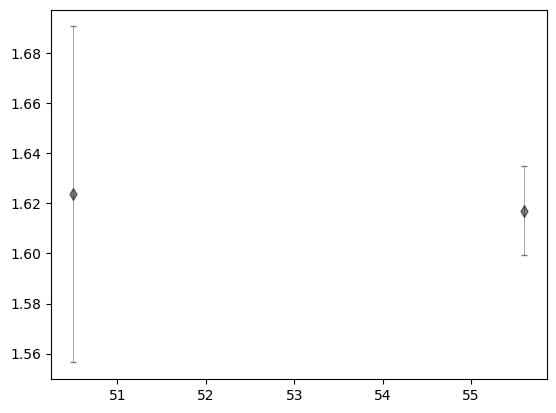

In [55]:
plt.scatter(ILSpacingsExperimentalHRTEM['Nb']
              ,ILSpacingsExperimentalHRTEM[('mean','d_tK')],
              label='HR-TEM, Nb-Ni, this study',color='black',alpha=0.5,marker='d')
plt.errorbar(ILSpacingsExperimentalHRTEM['Nb']
              ,ILSpacingsExperimentalHRTEM[('mean','d_tK')],yerr=ILSpacingsExperimentalHRTEM[ ('standard_deviation','d_tK')],capsize=2,
                   markersize=5,
                   color='black',linewidth = 0,elinewidth = 0.5,alpha=0.5)

In [56]:
def colored_line(x, y, c, ax, **lc_kwargs):
    """
    Plot a line with a color specified along the line by a third value.

    It does this by creating a collection of line segments. Each line segment is
    made up of two straight lines each connecting the current (x, y) point to the
    midpoints of the lines connecting the current point with its two neighbors.
    This creates a smooth line with no gaps between the line segments.

    Parameters
    ----------
    x, y : array-like
        The horizontal and vertical coordinates of the data points.
    c : array-like
        The color values, which should be the same size as x and y.
    ax : Axes
        Axis object on which to plot the colored line.
    **lc_kwargs
        Any additional arguments to pass to matplotlib.collections.LineCollection
        constructor. This should not include the array keyword argument because
        that is set to the color argument. If provided, it will be overridden.

    Returns
    -------
    matplotlib.collections.LineCollection
        The generated line collection representing the colored line.
    """
    if "array" in lc_kwargs:
        warnings.warn('The provided "array" keyword argument will be overridden')

    # Default the capstyle to butt so that the line segments smoothly line up
    default_kwargs = {"capstyle": "butt"}
    default_kwargs.update(lc_kwargs)

    # Compute the midpoints of the line segments. Include the first and last points
    # twice so we don't need any special syntax later to handle them.
    x = np.asarray(x)
    y = np.asarray(y)
    x_midpts = np.hstack((x[0], 0.5 * (x[1:] + x[:-1]), x[-1]))
    y_midpts = np.hstack((y[0], 0.5 * (y[1:] + y[:-1]), y[-1]))

    # Determine the start, middle, and end coordinate pair of each line segment.
    # Use the reshape to add an extra dimension so each pair of points is in its
    # own list. Then concatenate them to create:
    # [
    #   [(x1_start, y1_start), (x1_mid, y1_mid), (x1_end, y1_end)],
    #   [(x2_start, y2_start), (x2_mid, y2_mid), (x2_end, y2_end)],
    #   ...
    # ]
    coord_start = np.column_stack((x_midpts[:-1], y_midpts[:-1]))[:, np.newaxis, :]
    coord_mid = np.column_stack((x, y))[:, np.newaxis, :]
    coord_end = np.column_stack((x_midpts[1:], y_midpts[1:]))[:, np.newaxis, :]
    segments = np.concatenate((coord_start, coord_mid, coord_end), axis=1)

    lc = LineCollection(segments, **default_kwargs)
    lc.set_array(c)  # set the colors of each segment

    return ax.add_collection(lc)

In [57]:
exportFolder

WindowsPath('I:/sciebo/Paper6_OccupancyAndEffectsInNbNi/muphase_stuff - Kopie/muPhaseEval_results')

TypeError: 'module' object is not subscriptable

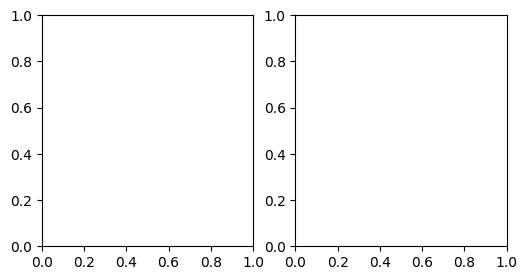

In [58]:
import seaborn as sns
fig,ax = plt.subplots(1,2,figsize=(6,3))
sns[0].scatter(dfLattice['Nb'],dfLattice['a'])
ax[1].scatter(dfLattice['Nb'],dfLattice['c'])

<AxesSubplot:xlabel='Ni/Nb', ylabel='a'>

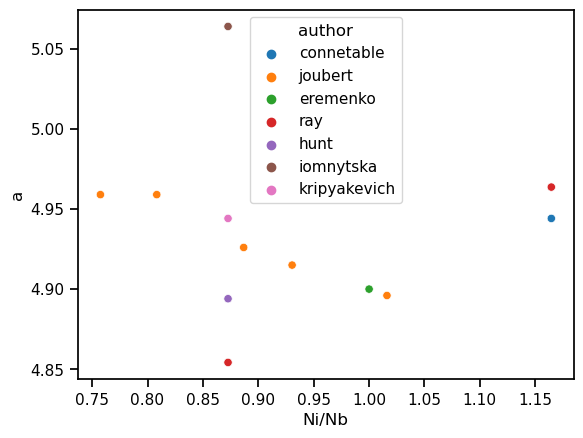

In [ ]:
sns.set_context("notebook")
sns.scatterplot(x='Ni/Nb',y='a',data=dfLattice,hue='author')

# plt.set_title('a')

<AxesSubplot:xlabel='Ni/Nb', ylabel='c'>

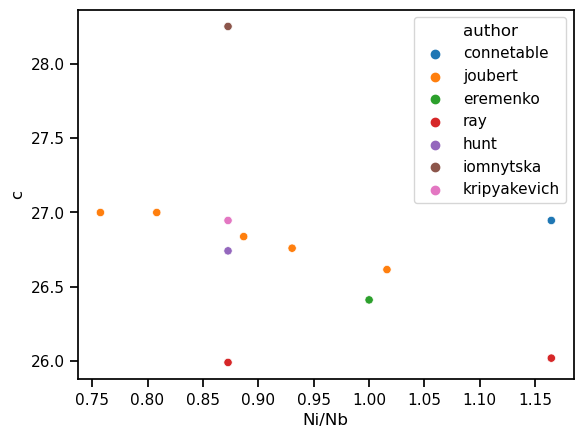

In [ ]:
sns.scatterplot(x='Ni/Nb',y='c',data=dfLattice,hue='author')

Nb-42Ni-v1
Nb-42Ni-v2
Nb-45Ni-v1
Nb-49Ni-v1
Nb-49Ni-v2
Nb-39Ni-10Al-v1
Nb-29Ni-20Al-v1
Nb-38Ni-8Cu-v1
Nb-30Ni-15Cu-v1


(25.95, 27.5)

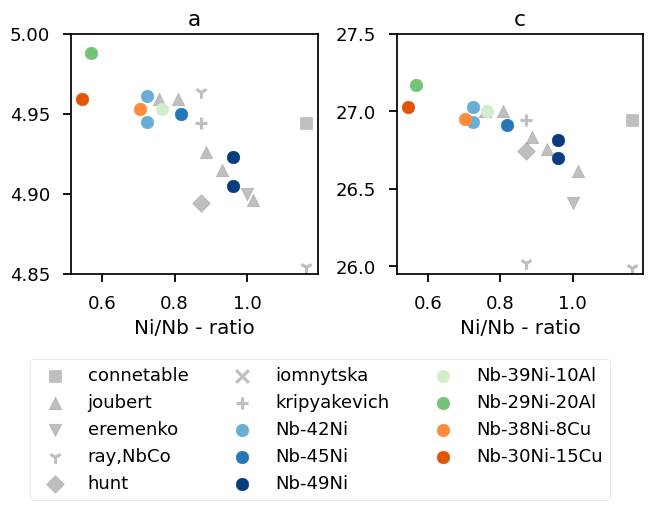

In [ ]:
results=pd.read_csv('C:\\Users\\berners\\sciebo\\C04\\Nb-Ni alloys\\xy\\results.txt',sep='\t')
import matplotlib as mpl
plt.style.use('seaborn-talk')
plt.rcParams['xtick.labelsize']=13
plt.rcParams['ytick.labelsize']=13
cm=1/2.54 
fig,ax=plt.subplots(1,2,figsize=(17*cm,8*cm))
# import seaborn as sns
# color=['gray','red','blue']
rgb_temp = mpl.cm.get_cmap('Blues')#[np.newaxis, :, :3]
# np.append(rgb,[[0,0,0,1]],axis=0)
rgb_temp=rgb_temp(np.linspace(0.5,0.95,3))

rgb=np.array([rgb_temp[0],rgb_temp[0],rgb_temp[1],rgb_temp[2],rgb_temp[2]])

gnbu=mpl.cm.get_cmap('Greens')
gnbu=gnbu(np.linspace(0.2,0.5,2))

pubu=mpl.cm.get_cmap('Oranges')
pubu=pubu(np.linspace(0.5,0.7,2))

rgb =np.append(rgb,gnbu,axis=0)

rgb =np.append(rgb,pubu,axis=0)
rgb= np.append(rgb,[[0,0,0,1]],axis=0)
# rgb=np.append()
# colors=mp
i=0
# ax_twin=ax.twinx()
markerList = ['s','^','v','1','D','x','+']
count = 0
for key in dfLattice['author'].unique():
    dfPlot = dfLattice[dfLattice['author']==key]
    # if i == 1:
    ax[0].scatter(dfPlot['Ni/Nb'],dfPlot['a'],alpha = 0.5,color='gray',label = key ,marker = markerList[count])
    ax[1].scatter(dfPlot['Ni/Nb'],dfPlot['c'],alpha = 0.5,color='gray',label = key,marker = markerList[count])  
    # else:
    #     ax[0].scatter(dfPlot['Ni/Nb'],dfPlot['a'],alpha = 0.5,color='gray',marker = markerList[count])
    #     ax[1].scatter(dfPlot['Ni/Nb'],dfPlot['c'],alpha = 0.5,color='gray',marker = markerList[count])  
    count = count+1
for key in results['sample'].unique():
    print(key)
    data=results[results['sample']==key]
    if i==1 or i ==3:
        ax[0].scatter(data['Ni']/data['Nb'],data['a'],color=rgb[i])
        ax[1].scatter(data['Ni']/data['Nb'],data['c'],color=rgb[i])

    else:
        ax[0].scatter(data['Ni']/data['Nb'],data['a'],color=rgb[i])
        ax[1].scatter(data['Ni']/data['Nb'],data['c'],color=rgb[i],label=key[:-3])

    i=i+1


fig.tight_layout()
ax[1].legend(loc='center right',ncol=3,bbox_to_anchor=(0.9,-0.65))
# ax[0].set_ylabel('Lattice parameter a')
ax[0].set_title('a')
ax[1].set_title('c')
# ax[1].set_yticks([26.7,26.9,27.1])
# ax[0].set_xticks([0.6,0.7,0.8,0.9])
ax[0].set_xlabel('Ni/Nb - ratio')
ax[1].set_xlabel('Ni/Nb - ratio')

ax[0].set_ylim([4.85,5])
# ax[1].set_ylim([26.5,27.3])
ax[1].set_ylim([25.95,27.5])

In [ ]:
dfLattice

,phase,a,c,Nb,Ni,author,Ni/Nb
0,Nb462Ni534_matProj_connetable,4.944122,26.94451,46.2,53.8,connetable,1.164502
1,Nb496Ni504_joubert,4.896000,26.61400,49.6,50.4,joubert,1.016129
2,Nb500Ni500_Eremenko_ILSpacings,4.900000,26.41000,50.0,50.0,eremenko,1.000000
3,Nb518Ni482_joubert,4.915000,26.75800,51.8,48.2,joubert,0.930502
4,Nb530Ni470_joubert,4.926000,26.83600,53.0,47.0,joubert,0.886792
5,Nb7Co6_em_relaxed_ray,4.963700,26.01820,53.4,46.6,ray,0.872659
6,Nb6Co7_em_relaxed_ray,4.854200,25.98910,46.2,53.8,ray,1.164502
7,Nb534Ni462_Hunt,4.894000,26.74000,53.4,46.6,hunt,0.872659
8,Nb534Ni462_lomnytska,5.064000,28.25000,53.4,46.6,iomnytska,0.872659
9,Nb534Ni462_matProj_kripyakevich,4.944122,26.94451,53.4,46.6,kripyakevich,0.872659
